# 03A · Designing the geo experiment

**The idea, simply:** switch quick-commerce (QC) ads **off** in 2 cities for 8 weeks (weeks 88–95),
keep them **on** in the other 6, and compare. If the paused cities' quick-commerce sales fall
below what they "should" have been, that gap is the ads' true effect. No model assumptions needed.

**Why QC ads?** The rule set in notebook 02B: test the channel whose uncertainty puts the most
money at risk. MMM v1 says QC ads earn ₹0.71 per ₹1, but anywhere from 0.14 to 3.49, on
₹8.9 Cr of spend (₹29.7 Cr uncertain), the largest of the six channels.

**What this notebook decides, before any test data exists:**
1. Which 2 cities to pause (they must be predictable from the other 6).
2. How big an effect the test can detect (power analysis by simulation).
3. What the test costs the business.
The answers are then written into the pre-registration (`preregistration/`).

In [ ]:
# Colab set-up: run this first (skipped automatically outside Colab)
import sys, os
if "google.colab" in sys.modules:
    REPO_URL = "https://github.com/anvesha2402/prakriti-growth-measurement.git"   # change if your repo differs
    if not os.path.exists("/content/repo"):
        get_ipython().system(f"git clone {REPO_URL} /content/repo")
    os.chdir("/content/repo")
    get_ipython().system("pip install -q 'pymc-marketing==1.1.*' statsmodels h5netcdf")


In [1]:
import sys, json, itertools
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import nnls
from scipy.stats import norm
from common import load, COLOR, INK, INK2, NEUTRAL, style, save, ROOT

style()
w, _ = load()
METRIC = "rev_quick_commerce_lakh"          # QC ads can only move quick-commerce sales: the most sensitive metric
Y = w.pivot(index="week", columns="geo", values=METRIC)
SPEND = w.pivot(index="week", columns="geo", values="spend_qc_ads_lakh")
GEOS = list(Y.columns)
TEST_WEEKS = 8
FIT_WEEKS = 26
ALPHA, POWER = 0.05, 0.80
Z = norm.ppf(1 - ALPHA / 2) + norm.ppf(POWER)
roi_v1 = pd.read_csv(ROOT / "model" / "mmm_v1_roi.csv").set_index("channel").loc["Quick-commerce ads"]
print(f"MMM v1 belief about QC ads ROI: median {roi_v1.roi:.2f}, 90% interval {roi_v1.roi_lo:.2f}–{roi_v1.roi_hi:.2f}")

MMM v1 belief about QC ads ROI: median 0.71, 90% interval 0.14–3.49


## 1. How the test will be read: synthetic control
For the paused cities, build a **"twin"**: a weighted mix of the 6 untouched cities that tracked
the paused cities closely in the 26 weeks before the test. During the test, the twin shows what
would have happened without the pause. Effect = paused cities − twin.

In [2]:
def synth_gap(treated, start, length=TEST_WEEKS, fit=FIT_WEEKS, y=Y):
    """Average weekly gap (treated − twin) over [start, start+length), twin fitted on the `fit` weeks before."""
    ctrl = [g for g in GEOS if g not in treated]
    fw = range(start - fit, start)
    tw = range(start, start + length)
    T_fit = y.loc[fw, treated].sum(1).values
    W, _ = nnls(y.loc[fw, ctrl].values, T_fit)
    pre_gap = T_fit - y.loc[fw, ctrl].values @ W
    T_test = y.loc[tw, treated].sum(1).values
    gap = T_test - y.loc[tw, ctrl].values @ W
    return gap.mean() - pre_gap.mean(), W, np.sqrt(np.mean(pre_gap**2)) / T_fit.mean()

## 2. Power by simulation (placebo tests)
Pretend a test happened at many past moments when *nothing* actually changed. The spread of those
fake "effects" is pure noise. A real effect must be clearly bigger than that noise.
**Minimum detectable effect (MDE)** = 2.8 × noise spread (5% false-alarm rate, 80% chance of catching a real effect).

In [3]:
starts = range(1 + FIT_WEEKS, 87 - TEST_WEEKS + 2)          # every possible 8-week window inside weeks 1–87

def evaluate(treated):
    placebo = np.array([synth_gap(list(treated), s)[0] for s in starts])
    se = placebo.std(ddof=1)
    mde_week = Z * se                                            # ₹ lakh per week, for the treated cities together
    weekly_spend = SPEND.loc[80:87, list(treated)].sum(1).mean() # recent weekly QC ad spend to be withheld
    withheld = weekly_spend * TEST_WEEKS
    _, _, fit_err = synth_gap(list(treated), 80)
    base = Y.loc[80:87, list(treated)].sum(1).mean()
    return dict(treated=" + ".join(treated), noise_se_lakh_wk=se, mde_lakh_wk=mde_week,
                mde_pct_of_qc_sales=mde_week / base, spend_withheld_lakh=withheld,
                mde_roi=mde_week * TEST_WEEKS / withheld, twin_fit_error=fit_err,
                share_of_company_qc_sales=base / Y.loc[80:87].sum(1).mean())

pairs = pd.DataFrame([evaluate(p) for p in itertools.combinations(GEOS, 2)]).sort_values("mde_roi")
pairs.head(8).round(3)

/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.lo

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

...

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.lo

/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.lo

/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.lo

,treated,noise_se_lakh_wk,mde_lakh_wk,mde_pct_of_qc_sales,spend_withheld_lakh,mde_roi,twin_fit_error,share_of_company_qc_sales
9,Bengaluru + Hyderabad,0.142,0.397,0.011,42.009,0.076,0.013,0.268
7,Bengaluru + Chennai,0.218,0.611,0.018,41.686,0.117,0.011,0.267
6,Ahmedabad + Pune,0.127,0.356,0.016,22.928,0.124,0.010,0.170
10,Bengaluru + Kolkata,0.213,0.596,0.018,37.875,0.126,0.012,0.250
11,Bengaluru + Mumbai,0.319,0.893,0.020,53.640,0.133,0.011,0.348
26,Kolkata + Pune,0.151,0.424,0.019,23.466,0.145,0.013,0.171
0,Ahmedabad + Bengaluru,0.243,0.680,0.021,37.337,0.146,0.018,0.249
24,Hyderabad + Pune,0.185,0.519,0.021,27.600,0.150,0.012,0.189


**How to read `mde_roi`:** the smallest true ROI the test can reliably detect. If QC ads truly return
₹0.71 per ₹1 (MMM v1's median), a design with `mde_roi` near or below 0.7 will usually catch it.

In [4]:
best = pairs.iloc[0]
treated = best.treated.split(" + ")
print(f"Chosen cities to pause: {treated}")
print(f"Detects a true ROI of {best.mde_roi:.2f} or more (80% power, 5% false-alarm rate).")
print(f"That equals a {best.mde_pct_of_qc_sales:.1%} drop in those cities' quick-commerce sales.")
print(f"Twin fit error before the test: {best.twin_fit_error:.1%} of weekly QC sales.")

Chosen cities to pause: ['Bengaluru', 'Hyderabad']
Detects a true ROI of 0.08 or more (80% power, 5% false-alarm rate).
That equals a 1.1% drop in those cities' quick-commerce sales.
Twin fit error before the test: 1.3% of weekly QC sales.


## 3. Is the test strong enough across what MMM v1 believes?
Power = chance the test detects the effect, for each plausible true ROI.

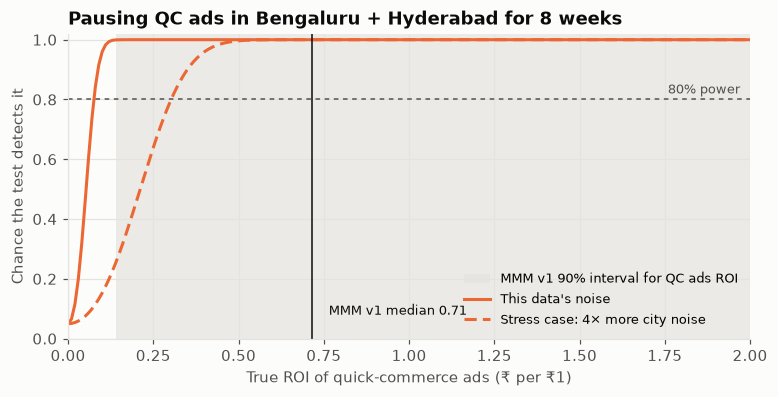

Power if the true ROI equals MMM v1's median (0.71): 100%; stress case: 100%


In [5]:
roi_grid = np.linspace(0, 3.5, 351)
eff_week = roi_grid * best.spend_withheld_lakh / TEST_WEEKS
def power_curve(se):
    z = norm.ppf(1 - ALPHA / 2)
    return norm.cdf(eff_week / se - z) + norm.cdf(-eff_week / se - z)
power = power_curve(best.noise_se_lakh_wk)
power_real = power_curve(4 * best.noise_se_lakh_wk)            # stress case: real-world city noise ~4x higher
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axvspan(roi_v1.roi_lo, roi_v1.roi_hi, color="#e4e3df", alpha=0.7, lw=0, label="MMM v1 90% interval for QC ads ROI")
ax.plot(roi_grid, power, color=COLOR["qc_ads"], label="This data's noise")
ax.plot(roi_grid, power_real, color=COLOR["qc_ads"], ls=(0, (4, 2)), label="Stress case: 4× more city noise")
ax.axhline(POWER, color=INK2, lw=1, ls=(0, (3, 3)))
ax.axvline(roi_v1.roi, color=INK, lw=1)
ax.text(roi_v1.roi + 0.05, 0.08, f"MMM v1 median {roi_v1.roi:.2f}", fontsize=8.5, color=INK)
ax.text(1.97, POWER + 0.02, "80% power", ha="right", fontsize=8.5, color=INK2)
ax.set_xlabel("True ROI of quick-commerce ads (₹ per ₹1)"); ax.set_ylabel("Chance the test detects it")
ax.set_ylim(0, 1.02); ax.set_xlim(0, 2); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
ax.set_title(f"Pausing QC ads in {' + '.join(treated)} for 8 weeks")
save(fig, "03A_power_curve"); plt.show()
p_at_median = float(np.interp(roi_v1.roi, roi_grid, power))
print(f"Power if the true ROI equals MMM v1's median ({roi_v1.roi:.2f}): {p_at_median:.0%}; "
      f"stress case: {float(np.interp(roi_v1.roi, roi_grid, power_real)):.0%}")

## 4. Pre-test check: does the twin track the paused cities?

/tmp/ipykernel_345/2783913618.py:6: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_fit = y.loc[fw, treated].sum(1).values
/tmp/ipykernel_345/2783913618.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_test = y.loc[tw, treated].sum(1).values
/tmp/ipykernel_345/1389946993.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T = Y.loc[fw, treated].sum(1)


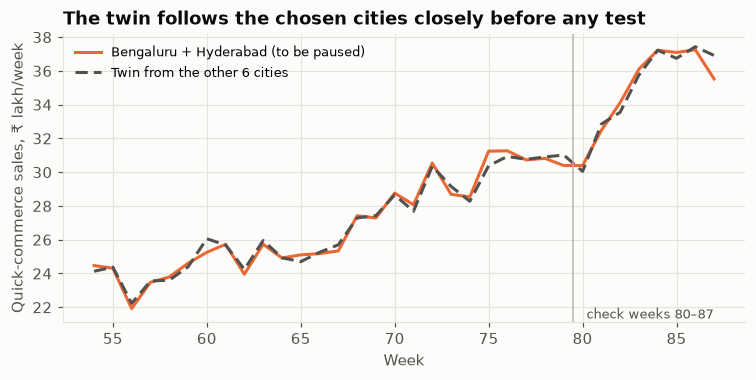

Twin weights: {'Ahmedabad': 0.65, 'Delhi NCR': 0.267, 'Kolkata': 0.587, 'Pune': 1.271}
Average gap in check weeks 80–87 (should be ≈ 0): -0.04 ₹ lakh/week


In [6]:
gap, W, _ = synth_gap(treated, 80, length=8)
ctrl = [g for g in GEOS if g not in treated]
fw = range(80 - FIT_WEEKS, 88)
T = Y.loc[fw, treated].sum(1)
S = pd.Series(Y.loc[fw, ctrl].values @ W, index=list(fw))
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(T.index, T.values, color=COLOR["qc_ads"], label=f"{' + '.join(treated)} (to be paused)")
ax.plot(S.index, S.values, color=INK2, ls=(0, (4, 2)), label="Twin from the other 6 cities")
ax.axvline(79.5, color=NEUTRAL, lw=1)
ax.text(80, ax.get_ylim()[0], " check weeks 80–87", va="bottom", fontsize=8.5, color=INK2)
ax.set_xlabel("Week"); ax.set_ylabel("Quick-commerce sales, ₹ lakh/week")
ax.legend(frameon=False, fontsize=8.5, loc="upper left")
ax.set_title("The twin follows the chosen cities closely before any test")
save(fig, "03A_twin_pretest"); plt.show()
weights = pd.Series(W, index=ctrl).round(3)
print("Twin weights:", weights[weights > 0].to_dict())
print(f"Average gap in check weeks 80–87 (should be ≈ 0): {gap:+.2f} ₹ lakh/week")

## 5. What does the test cost the business?
Pausing saves the ad spend but loses whatever sales the ads truly drive. Contribution margin on
quick-commerce sales after the platform commission: about 30% of revenue (benchmark register).

In [7]:
QC_MARGIN = 0.30
rows = []
for label, r in [("MMM v1 low (5%)", roi_v1.roi_lo), ("MMM v1 median", roi_v1.roi), ("MMM v1 high (95%)", roi_v1.roi_hi)]:
    lost_rev = r * best.spend_withheld_lakh
    net = best.spend_withheld_lakh - lost_rev * QC_MARGIN          # + = test saves money
    rows.append(dict(scenario=label, true_roi=r, spend_saved_lakh=best.spend_withheld_lakh,
                     revenue_lost_lakh=lost_rev, contribution_effect_lakh=net))
cost = pd.DataFrame(rows).set_index("scenario").round(1)
cost

,true_roi,spend_saved_lakh,revenue_lost_lakh,contribution_effect_lakh
scenario,,,,
MMM v1 low (5%),0.1,42.0,6.0,40.2
MMM v1 median,0.7,42.0,30.0,33.0
MMM v1 high (95%),3.5,42.0,146.6,-2.0


## 6. Save the design for pre-registration

In [8]:
design = {"channel": "qc_ads", "treated_geos": treated, "weeks": [88, 95]}
pre = ROOT / "preregistration"; pre.mkdir(exist_ok=True)
(pre / "design.json").write_text(json.dumps(design, indent=1))
summary = dict(design=design, metric=METRIC, alpha=ALPHA, power_target=POWER, fit_weeks=FIT_WEEKS,
               noise_se_lakh_per_week=round(best.noise_se_lakh_wk, 3), mde_lakh_per_week=round(best.mde_lakh_wk, 3),
               mde_roi=round(best.mde_roi, 3), mde_pct_of_qc_sales=round(best.mde_pct_of_qc_sales, 4),
               expected_spend_withheld_lakh=round(best.spend_withheld_lakh, 2),
               power_at_mmm_v1_median=round(p_at_median, 3), twin_weights=weights[weights > 0].to_dict(),
               placebo_windows=len(list(starts)))
(pre / "design_summary.json").write_text(json.dumps(summary, indent=1))
print(json.dumps(summary, indent=1))

{
 "design": {
  "channel": "qc_ads",
  "treated_geos": [
   "Bengaluru",
   "Hyderabad"
  ],
  "weeks": [
   88,
   95
  ]
 },
 "metric": "rev_quick_commerce_lakh",
 "alpha": 0.05,
 "power_target": 0.8,
 "fit_weeks": 26,
 "noise_se_lakh_per_week": 0.142,
 "mde_lakh_per_week": 0.397,
 "mde_roi": 0.076,
 "mde_pct_of_qc_sales": 0.0113,
 "expected_spend_withheld_lakh": 42.01,
 "power_at_mmm_v1_median": 1.0,
 "twin_weights": {
  "Ahmedabad": 0.65,
  "Delhi NCR": 0.267,
  "Kolkata": 0.587,
  "Pune": 1.271
 },
 "placebo_windows": 54
}


## 7. So what

In [9]:
print("SO WHAT")
print(f"1. Decision: pause quick-commerce ads in {' and '.join(treated)} for weeks 88–95; the other 6 cities form the comparison.")
print(f"2. Sensitivity: the test detects a true ROI of {best.mde_roi:.2f}+ ({best.mde_pct_of_qc_sales:.1%} of those cities' QC sales); "
      f"{p_at_median:.0%} power at MMM v1's median of {roi_v1.roi:.2f}; with 4× more city noise it still detects ROI ≈ 0.3+.")
c = cost.loc["MMM v1 median"]
print(f"3. Cost: ₹{best.spend_withheld_lakh:.0f} lakh of ad spend is withheld. At the median belief the test "
      f"{'saves' if c.contribution_effect_lakh > 0 else 'costs'} about ₹{abs(c.contribution_effect_lakh):.0f} lakh of contribution; "
      f"even at the high end it costs only ₹{abs(min(0, cost.contribution_effect_lakh.min())):.0f} lakh.")
print("4. Caveat: city-level noise in this synthetic data is low (about 1.5% a week once national swings are removed). "
      "Real markets add local shocks (stock-outs, weather, events), so a real test of this size would be roughly "
      "3–5× less sensitive. The 2-city, 8-week design keeps a margin for that.")

SO WHAT
1. Decision: pause quick-commerce ads in Bengaluru and Hyderabad for weeks 88–95; the other 6 cities form the comparison.
2. Sensitivity: the test detects a true ROI of 0.08+ (1.1% of those cities' QC sales); 100% power at MMM v1's median of 0.71; with 4× more city noise it still detects ROI ≈ 0.3+.
3. Cost: ₹42 lakh of ad spend is withheld. At the median belief the test saves about ₹33 lakh of contribution; even at the high end it costs only ₹2 lakh.
4. Caveat: city-level noise in this synthetic data is low (about 1.5% a week once national swings are removed). Real markets add local shocks (stock-outs, weather, events), so a real test of this size would be roughly 3–5× less sensitive. The 2-city, 8-week design keeps a margin for that.
